<a href="https://colab.research.google.com/github/Sandhiya962007/CN_Web_Attack_Classifier/blob/main/CN_WEB_ATTACK_CLASSIFIER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
import os

base_path = '/content/drive/MyDrive/CN_Web_Attack_Project'

for root, dirs, files in os.walk(base_path):
    for file in files:
        if 'Thursday' in file and 'WebAttacks' in file:
            print("File found!")
            print("Full path:", os.path.join(root, file))

File found!
Full path: /content/drive/MyDrive/CN_Web_Attack_Project/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
File found!
Full path: /content/drive/MyDrive/CN_Web_Attack_Project/Copy of Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv


In [10]:
file_path = "/content/drive/MyDrive/CN_Web_Attack_Project/Copy of Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"

df = pd.read_csv(
    file_path,
    encoding="latin1",
    low_memory=False
)

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

print("\nFirst five rows:")

display(df.head())

Dataset loaded successfully!
Dataset shape: (458968, 85)

First five rows:


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.3-192.168.10.50-389-33898-6,192.168.10.50,33898.0,192.168.10.3,389.0,6.0,6/7/2017 8:59,113095465.0,48.0,24.0,...,32.0,203985.500,5.758373e+05,1629110.0,379.0,13800000.0,4.277541e+06,16500000.0,6737603.0,BENIGN
1,192.168.10.3-192.168.10.50-389-33904-6,192.168.10.50,33904.0,192.168.10.3,389.0,6.0,6/7/2017 8:59,113473706.0,68.0,40.0,...,32.0,178326.875,5.034269e+05,1424245.0,325.0,13800000.0,4.229413e+06,16500000.0,6945512.0,BENIGN
2,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0.0,8.0.6.4,0.0,0.0,6/7/2017 8:59,119945515.0,150.0,0.0,...,0.0,6909777.333,1.170000e+07,20400000.0,6.0,24400000.0,2.430000e+07,60100000.0,5702188.0,BENIGN
3,192.168.10.14-65.55.44.109-59135-443-6,192.168.10.14,59135.0,65.55.44.109,443.0,6.0,6/7/2017 8:59,60261928.0,9.0,7.0,...,20.0,0.000,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0,0.0,BENIGN
4,192.168.10.3-192.168.10.14-53-59555-17,192.168.10.14,59555.0,192.168.10.3,53.0,17.0,6/7/2017 8:59,269.0,2.0,2.0,...,32.0,0.000,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0,0.0,BENIGN


In [11]:
# Clean column names
df.columns = df.columns.str.strip()

# Find the label column
print("Last few columns:", df.columns[-5:])

# Display attack categories
print("\nAttack categories:")

print(df["Label"].value_counts())

Last few columns: Index(['Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min', 'Label'], dtype='object')

Attack categories:
Label
BENIGN                        168186
Web Attack  Brute Force        1507
Web Attack  XSS                 652
Web Attack  Sql Injection        21
Name: count, dtype: int64


/tmp/ipykernel_687/3604460730.py:10: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


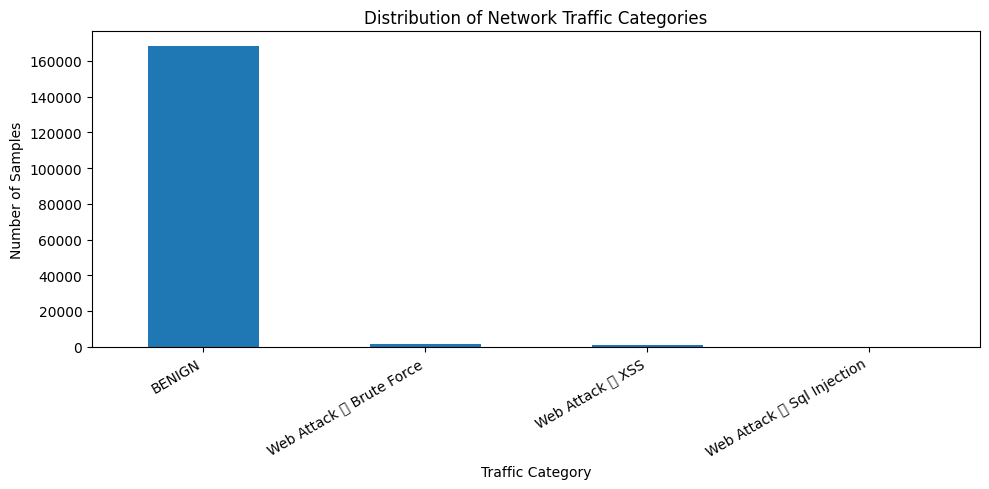

In [12]:
plt.figure(figsize=(10, 5))

df["Label"].value_counts().plot(kind="bar")

plt.title("Distribution of Network Traffic Categories")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Samples")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [13]:
# Remove unwanted spaces from column names

df.columns = df.columns.str.strip()

print("Column names cleaned successfully!")

print(df.columns.tolist())

Column names cleaned successfully!
['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN F

In [14]:
# Display unique attack labels

print("Available attack labels:")

print(df["Label"].unique())

Available attack labels:
['BENIGN' 'Web Attack \x96 Brute Force' 'Web Attack \x96 XSS'
 'Web Attack \x96 Sql Injection' nan]


In [15]:
# Normalize label formatting

df["Label"] = (
    df["Label"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace("–", "-", regex=False)
    .str.replace("—", "-", regex=False)
)

# Convert original labels into four project categories

def classify_attack(label):

    if label == "benign":
        return "BENIGN"

    elif "brute force" in label:
        return "Brute Force"

    elif "xss" in label:
        return "XSS"

    elif "sql injection" in label:
        return "SQL Injection"

    else:
        return None


df["Label"] = df["Label"].apply(classify_attack)

# Remove rows that do not belong to the four required categories

df = df.dropna(subset=["Label"]).copy()

print("\nStandardized attack categories:")

print(df["Label"].value_counts())


Standardized attack categories:
Label
BENIGN           168186
Brute Force        1507
XSS                 652
SQL Injection        21
Name: count, dtype: int64


In [16]:
import numpy as np

# Replace infinite values with NaN

df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Missing values in dataset:")

print(df.isnull().sum().sum())

print("\nInfinite values handled successfully!")

Missing values in dataset:
270

Infinite values handled successfully!


In [17]:
# Separate target variable

y = df["Label"]

# Remove label and identifying columns

columns_to_remove = [
    "Label",
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
]

X = df.drop(
    columns=columns_to_remove,
    errors="ignore"
)

# Select numerical features only

X = X.select_dtypes(include=[np.number])

print("Input features shape:", X.shape)

print("Output labels shape:", y.shape)

Input features shape: (170366, 80)
Output labels shape: (170366,)


In [18]:
print("Selected network features:")

for feature in X.columns:
    print(feature)

Selected network features:
Source Port
Destination Port
Protocol
Flow Duration
Total Fwd Packets
Total Backward Packets
Total Length of Fwd Packets
Total Length of Bwd Packets
Fwd Packet Length Max
Fwd Packet Length Min
Fwd Packet Length Mean
Fwd Packet Length Std
Bwd Packet Length Max
Bwd Packet Length Min
Bwd Packet Length Mean
Bwd Packet Length Std
Flow Bytes/s
Flow Packets/s
Flow IAT Mean
Flow IAT Std
Flow IAT Max
Flow IAT Min
Fwd IAT Total
Fwd IAT Mean
Fwd IAT Std
Fwd IAT Max
Fwd IAT Min
Bwd IAT Total
Bwd IAT Mean
Bwd IAT Std
Bwd IAT Max
Bwd IAT Min
Fwd PSH Flags
Bwd PSH Flags
Fwd URG Flags
Bwd URG Flags
Fwd Header Length
Bwd Header Length
Fwd Packets/s
Bwd Packets/s
Min Packet Length
Max Packet Length
Packet Length Mean
Packet Length Std
Packet Length Variance
FIN Flag Count
SYN Flag Count
RST Flag Count
PSH Flag Count
ACK Flag Count
URG Flag Count
CWE Flag Count
ECE Flag Count
Down/Up Ratio
Average Packet Size
Avg Fwd Segment Size
Avg Bwd Segment Size
Fwd Header Length.1
Fwd Avg

In [19]:
missing = X.isnull().sum()

print("Features containing missing values:")

print(missing[missing > 0])

print("\nTotal numerical features:", X.shape[1])

Features containing missing values:
Flow Bytes/s      135
Flow Packets/s    135
dtype: int64

Total numerical features: 80


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")

print("Training samples:", X_train.shape[0])

print("Testing samples:", X_test.shape[0])

print("Number of input features:", X_train.shape[1])

Training and testing split completed!
Training samples: 136292
Testing samples: 34074
Number of input features: 80


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Random Forest libraries imported successfully!")

Random Forest libraries imported successfully!


In [22]:
rf_model = Pipeline([

    # Handle missing values
    ("imputer", SimpleImputer(strategy="median")),

    # Random Forest classifier
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced_subsample",
        n_jobs=-1
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [23]:
print("Training Random Forest model...")

rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Training Random Forest model...
Random Forest training completed successfully!


In [25]:
y_pred = rf_model.predict(X_test)

print("Prediction completed successfully!")

print("\nFirst 100 predictions:")

print(y_pred[:100])

Prediction completed successfully!

First 100 predictions:
['BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'Brute Force'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'XSS' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN']


In [26]:
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:",
      round(accuracy * 100, 2), "%")

Random Forest Accuracy: 99.75 %


In [27]:
print("RANDOM FOREST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

RANDOM FOREST CLASSIFICATION REPORT
               precision    recall  f1-score   support

       BENIGN       1.00      1.00      1.00     33638
  Brute Force       0.86      0.90      0.88       302
SQL Injection       1.00      0.75      0.86         4
          XSS       0.74      0.62      0.68       130

     accuracy                           1.00     34074
    macro avg       0.90      0.82      0.85     34074
 weighted avg       1.00      1.00      1.00     34074



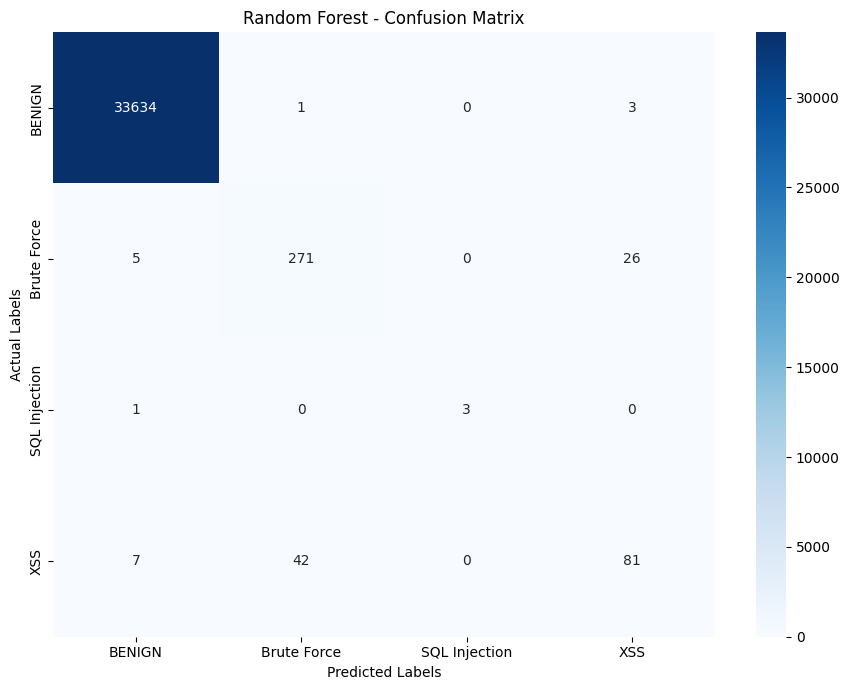

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = rf_model.named_steps["classifier"].classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.tight_layout()
plt.show()

In [29]:
import joblib

joblib.dump(
    rf_model,
    "/content/drive/MyDrive/CN_Web_Attack_Project/random_forest_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [30]:
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree library imported successfully!")

Decision Tree library imported successfully!


In [31]:
dt_model = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))

])

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [32]:
print("Training Decision Tree model...")

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Training Decision Tree model...
Decision Tree training completed!


In [34]:
dt_pred = dt_model.predict(X_test)

print("Decision Tree predictions completed!")

print(dt_pred[:100])

Decision Tree predictions completed!
['BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'Brute Force'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'XSS' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN']


In [35]:
dt_accuracy = accuracy_score(y_test, dt_pred)

print(
    "Decision Tree Accuracy:",
    round(dt_accuracy * 100, 2),
    "%"
)

Decision Tree Accuracy: 99.77 %


In [36]:
print("DECISION TREE CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        dt_pred,
        zero_division=0
    )
)

DECISION TREE CLASSIFICATION REPORT
               precision    recall  f1-score   support

       BENIGN       1.00      1.00      1.00     33638
  Brute Force       0.87      0.90      0.88       302
SQL Injection       1.00      1.00      1.00         4
          XSS       0.74      0.71      0.72       130

     accuracy                           1.00     34074
    macro avg       0.90      0.90      0.90     34074
 weighted avg       1.00      1.00      1.00     34074



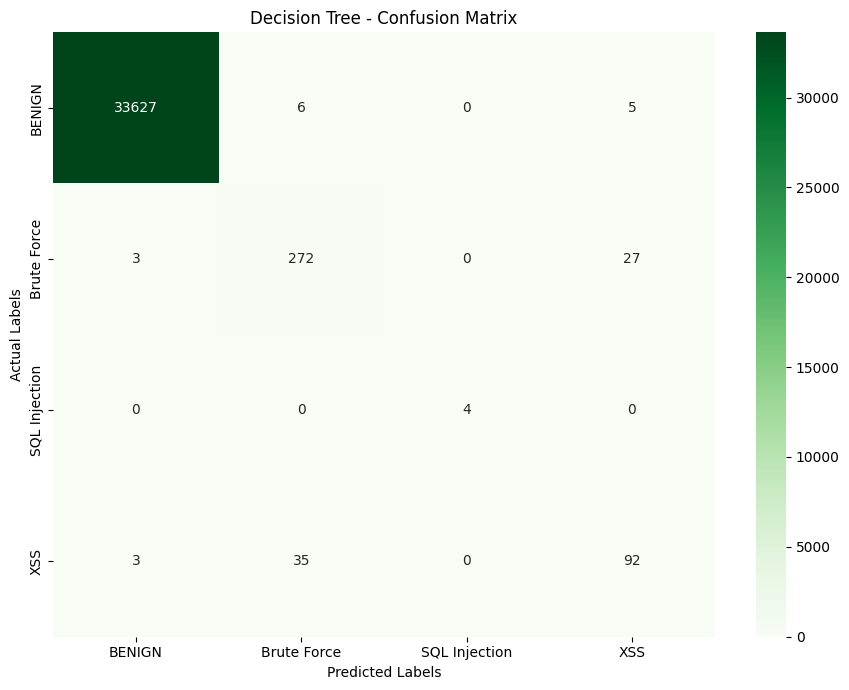

In [37]:
dt_labels = dt_model.named_steps["classifier"].classes_

dt_cm = confusion_matrix(
    y_test,
    dt_pred,
    labels=dt_labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=dt_labels,
    yticklabels=dt_labels
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.tight_layout()
plt.show()

       Algorithm  Accuracy (%)
0  Random Forest     99.750543
1  Decision Tree     99.768152


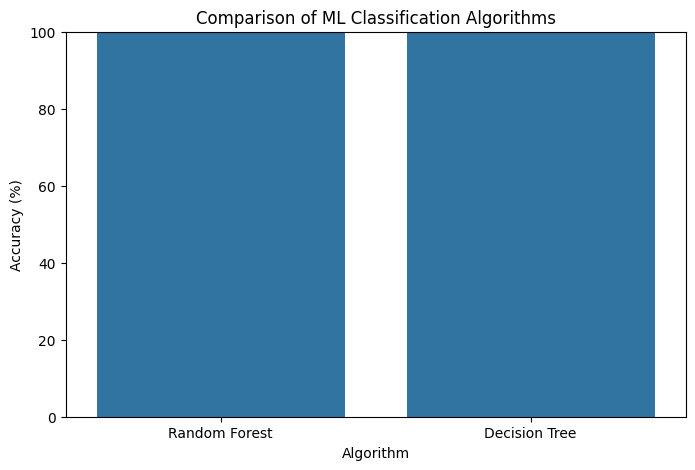

In [38]:
comparison = pd.DataFrame({
    "Algorithm": [
        "Random Forest",
        "Decision Tree"
    ],

    "Accuracy (%)": [
        accuracy * 100,
        dt_accuracy * 100
    ]
})

print(comparison)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Accuracy (%)"
)

plt.title("Comparison of ML Classification Algorithms")
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")

plt.show()

       Algorithm   Accuracy  Macro Precision  Macro Recall  Macro F1-score
0  Random Forest  99.750543              0.9          0.82            0.85
1  Decision Tree  99.768152              0.9          0.90            0.90


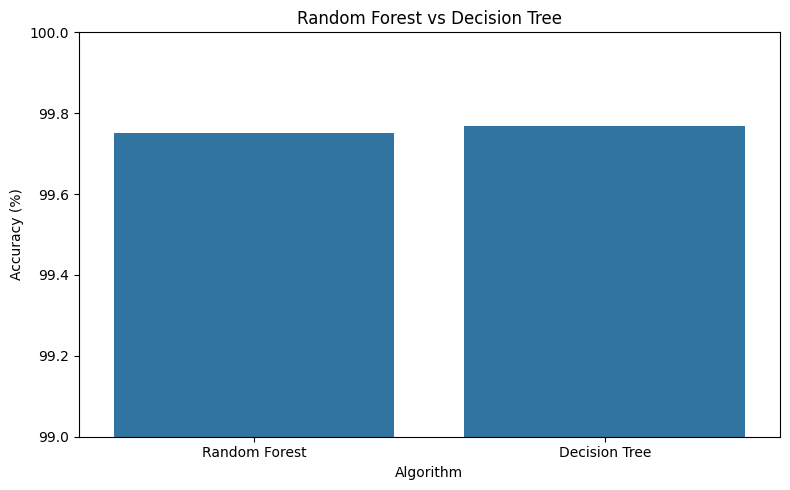

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create comparison table
comparison = pd.DataFrame({
    "Algorithm": ["Random Forest", "Decision Tree"],
    "Accuracy": [accuracy * 100, dt_accuracy * 100],
    "Macro Precision": [0.90, 0.90],
    "Macro Recall": [0.82, 0.90],
    "Macro F1-score": [0.85, 0.90]
})

print(comparison)

# Plot accuracy comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Accuracy"
)

plt.title("Random Forest vs Decision Tree")
plt.ylabel("Accuracy (%)")
plt.ylim(99, 100)

plt.tight_layout()
plt.show()

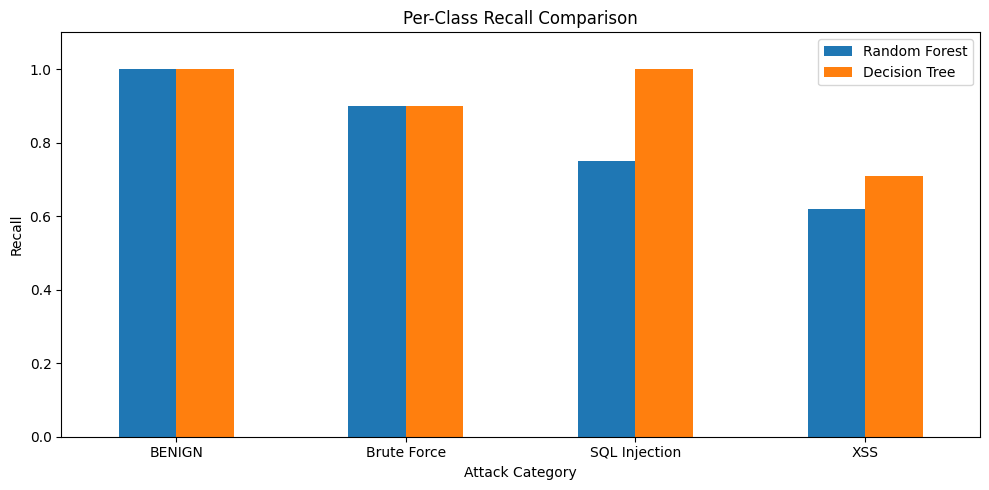

In [40]:
recall_comparison = pd.DataFrame({
    "Attack Category": [
        "BENIGN", "Brute Force", "SQL Injection", "XSS"
    ],
    "Random Forest": [1.00, 0.90, 0.75, 0.62],
    "Decision Tree": [1.00, 0.90, 1.00, 0.71]
})

recall_comparison.plot(
    x="Attack Category",
    y=["Random Forest", "Decision Tree"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Per-Class Recall Comparison")
plt.ylabel("Recall")
plt.xlabel("Attack Category")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

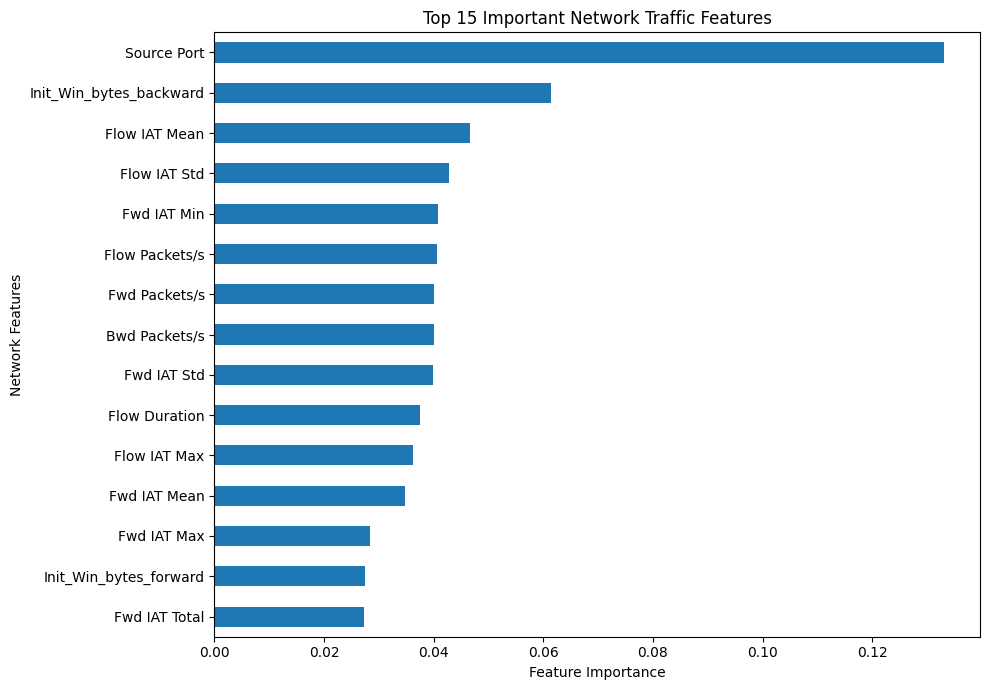

In [41]:
# Extract Random Forest feature importance

rf_classifier = rf_model.named_steps["classifier"]

importance = pd.Series(
    rf_classifier.feature_importances_,
    index=X_train.columns
)

# Select top 15 features

top_features = importance.sort_values(
    ascending=False
).head(15)

# Plot feature importance

plt.figure(figsize=(10, 7))

top_features.sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Important Network Traffic Features")
plt.xlabel("Feature Importance")
plt.ylabel("Network Features")

plt.tight_layout()
plt.show()

In [42]:
import joblib
import os

result_path = "/content/drive/MyDrive/CN_Web_Attack_Project/Results"

os.makedirs(result_path, exist_ok=True)

# Save models

joblib.dump(
    rf_model,
    result_path + "/Random_Forest_Model.pkl"
)

joblib.dump(
    dt_model,
    result_path + "/Decision_Tree_Model.pkl"
)

# Save comparison

comparison.to_csv(
    result_path + "/Algorithm_Comparison.csv",
    index=False
)

print("All models and comparison results saved!")

All models and comparison results saved!


In [43]:
# Random Forest report
rf_report = classification_report(
    y_test, y_pred,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(rf_report).transpose().to_csv(
    result_path + "/Random_Forest_Report.csv"
)

# Decision Tree report
dt_report = classification_report(
    y_test, dt_pred,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(dt_report).transpose().to_csv(
    result_path + "/Decision_Tree_Report.csv"
)

print("Both classification reports saved successfully!")

Both classification reports saved successfully!


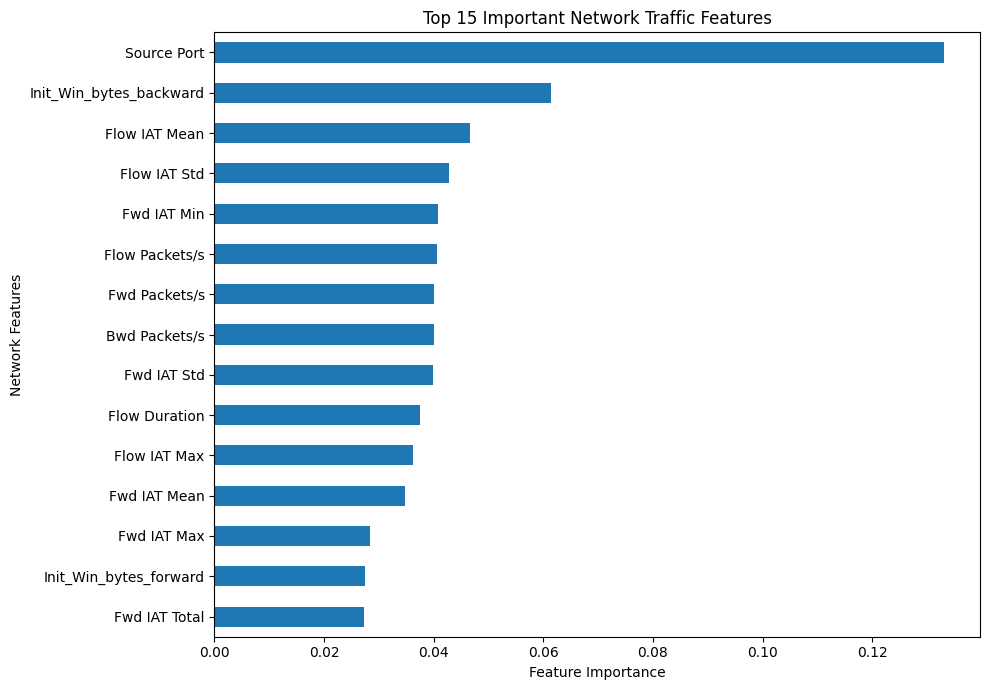

Feature importance graph saved!


In [44]:
import matplotlib.pyplot as plt
import pandas as pd
import os

result_path = "/content/drive/MyDrive/CN_Web_Attack_Project/Results"

# Extract Random Forest feature importance
rf_classifier = rf_model.named_steps["classifier"]

importance = pd.Series(
    rf_classifier.feature_importances_,
    index=X_train.columns
)

# Select top 15 features
top_features = importance.sort_values(
    ascending=False
).head(15)

# Plot
plt.figure(figsize=(10, 7))

top_features.sort_values().plot(kind="barh")

plt.title("Top 15 Important Network Traffic Features")
plt.xlabel("Feature Importance")
plt.ylabel("Network Features")

plt.tight_layout()

# Save graph
plt.savefig(
    result_path + "/Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance graph saved!")

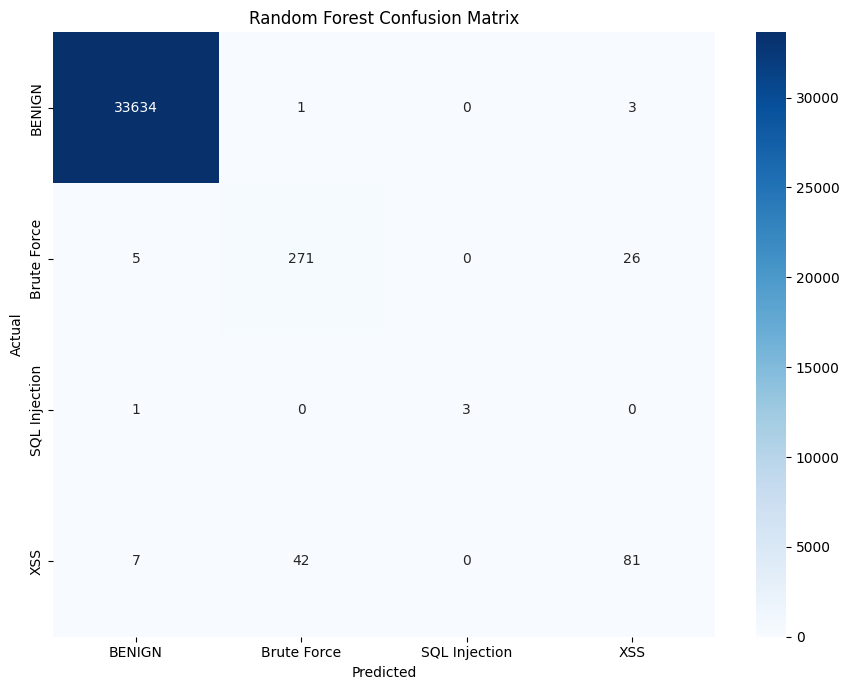

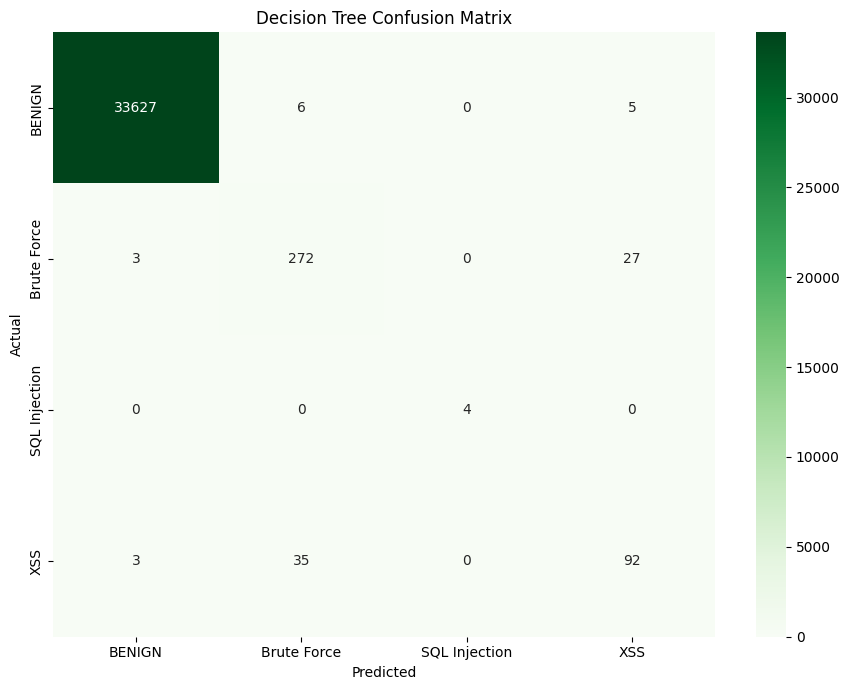

Both confusion matrix graphs saved!


In [45]:
# Random Forest confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    result_path + "/Random_Forest_Confusion_Matrix.png",
    dpi=300
)

plt.show()


# Decision Tree confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=dt_labels,
    yticklabels=dt_labels
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    result_path + "/Decision_Tree_Confusion_Matrix.png",
    dpi=300
)

plt.show()

print("Both confusion matrix graphs saved!")

In [46]:
# Select one test sample
sample = X_test.iloc[[0]]

# Actual category
actual = y_test.iloc[0]

# Predict using Random Forest
rf_prediction = rf_model.predict(sample)[0]

# Predict using Decision Tree
dt_prediction = dt_model.predict(sample)[0]

print("WEB ATTACK CLASSIFICATION DEMO")

print("--------------------------------")

print("Actual Category:", actual)

print("Random Forest Prediction:", rf_prediction)

print("Decision Tree Prediction:", dt_prediction)

WEB ATTACK CLASSIFICATION DEMO
--------------------------------
Actual Category: BENIGN
Random Forest Prediction: BENIGN
Decision Tree Prediction: BENIGN


In [47]:
# Select an XSS sample from test data
xss_sample = X_test[y_test == "XSS"].iloc[[0]]

print("Actual Attack: XSS")

print("Random Forest:",
      rf_model.predict(xss_sample)[0])

print("Decision Tree:",
      dt_model.predict(xss_sample)[0])

Actual Attack: XSS
Random Forest: XSS
Decision Tree: XSS
